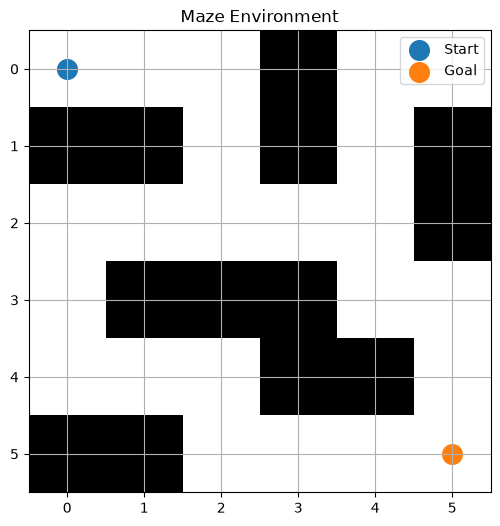

Actions: Up, Down, Left, Right
Goal Reward: +100
Wall Penalty: -5
Normal Movement: -1
Training completed!

Learned Path:
[(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (3, 5), (4, 5), (5, 5)]
Number of steps: 10
Goal reached successfully!


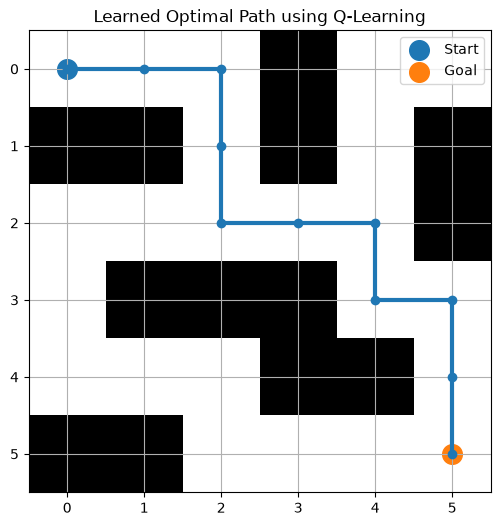

# Experiment No. 6
# Aim: Reinforcement Learning using Maze Environment

 Step 1: Import libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random


Step 2: Create and display Maze

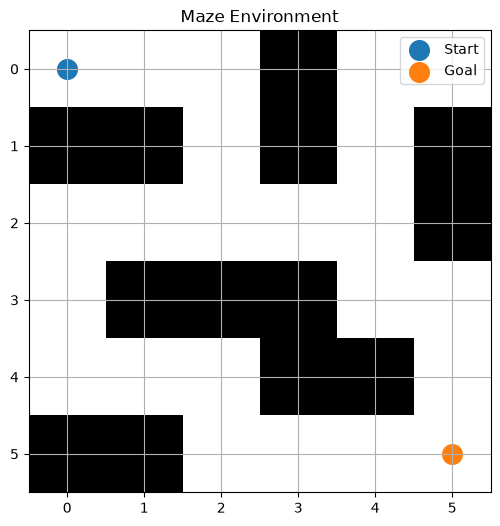

In [4]:
maze = np.array([
    [0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 1],
    [0, 1, 1, 1, 0, 0],
    [0, 0, 0, 1, 1, 0],
    [1, 1, 0, 0, 0, 0]
])

start = (0, 0)
goal = (5, 5)

plt.figure(figsize=(6, 6))
plt.imshow(maze, cmap="gray_r")

plt.scatter(start[1], start[0], s=200, label="Start")
plt.scatter(goal[1], goal[0], s=200, label="Goal")

plt.xticks(range(6))
plt.yticks(range(6))
plt.grid()
plt.legend()
plt.title("Maze Environment")
plt.show()


Step 3: Define actions and rewards

In [5]:
actions = {
    0: (-1, 0),  # Up
    1: (1, 0),   # Down
    2: (0, -1),  # Left
    3: (0, 1)    # Right
}

def move(state, action):

    r, c = state

    nr = r + actions[action][0]
    nc = c + actions[action][1]

    if nr < 0 or nr >= 6 or nc < 0 or nc >= 6 or maze[nr, nc] == 1:
        return state, -5

    if (nr, nc) == goal:
        return (nr, nc), 100

    return (nr, nc), -1


print("Actions: Up, Down, Left, Right")
print("Goal Reward: +100")
print("Wall Penalty: -5")
print("Normal Movement: -1")

Actions: Up, Down, Left, Right
Goal Reward: +100
Wall Penalty: -5
Normal Movement: -1


Step 4: Train agent using Q-Learning

In [6]:
Q = np.zeros((6, 6, 4))

alpha = 0.8
gamma = 0.95
epsilon = 1.0

for episode in range(1000):

    state = start

    for _ in range(100):

        if random.random() < epsilon:
            action = random.randint(0, 3)
        else:
            action = np.argmax(Q[state])

        new_state, reward = move(state, action)

        Q[state][action] += alpha * (
            reward + gamma * np.max(Q[new_state]) - Q[state][action]
        )

        state = new_state

        if state == goal:
            break

    epsilon *= 0.995

print("Training completed!")

Training completed!


Step 5: Find learned optimal path

In [7]:
state = start
path = [state]

for _ in range(50):

    action = np.argmax(Q[state])

    new_state, reward = move(state, action)

    if new_state == state:
        break

    state = new_state
    path.append(state)

    if state == goal:
        break

print("\nLearned Path:")
print(path)

print("Number of steps:", len(path) - 1)

if state == goal:
    print("Goal reached successfully!")
else:
    print("Goal not reached. Try training again.")



Learned Path:
[(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (3, 5), (4, 5), (5, 5)]
Number of steps: 10
Goal reached successfully!


Step 6: Display learned optimal path

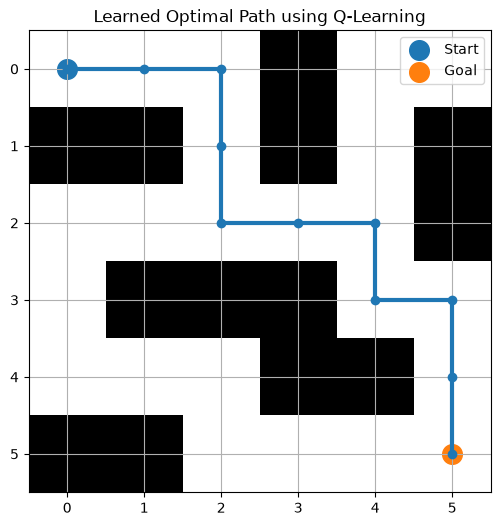

In [8]:
plt.figure(figsize=(6, 6))

plt.imshow(maze, cmap="gray_r")

rows = [p[0] for p in path]
cols = [p[1] for p in path]

plt.plot(cols, rows, marker="o", linewidth=3)

plt.scatter(start[1], start[0], s=200, label="Start")
plt.scatter(goal[1], goal[0], s=200, label="Goal")

plt.xticks(range(6))
plt.yticks(range(6))

plt.grid()
plt.legend()

plt.title("Learned Optimal Path using Q-Learning")

plt.show()
